<a href="https://colab.research.google.com/github/oliviaberset/2026_solute_transport/blob/main/Erlenbach_solute_transport_simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solute transport in a small pre-Alpine catchment: the Erlenbach (Alptal) hydrochemistry 2021

We use the tools from the previous exercises (data tidying and long format, seaborn overviews, conservative vs reactive solutes, linear mixing) on a new dataset: hourly samples during rain events at the outlets of two small sub-catchments of the Erlenbach.

Three activities:

- **Activity 1:** Where do the solutes come from? Compare rain, soil water, groundwater and stream water.
- **Activity 2:** How do different solute types respond to rain events?
- **Activity 3:** How much of the stream water is pre-event water? A two-component linear mixing model.

## The data

Bujak, I., von Freyberg, J., Rinaldo, A. and van Meerveld, I.: *Hydrochemical data collected during spring–fall 2021 in the Erlenbach catchment*, EnviDat (add year and DOI from the download page).

The Erlenbach (Alptal, Canton Schwyz, ~1100–1650 m a.s.l.) drains low-permeability Flysch with waterlogged gleysols, forest and wet grassland. The file contains samples from August to October 2021:

| Group | Location IDs | Sampling |
|---|---|---|
| Outlets | **CB1** (Chaspersboden sub-catchment), **L1** (Langried sub-catchment) | about hourly during rain events |
| Rain | **E2** (Erlenhöhe) | hourly during events |
| Groundwater | IDs with `GW` (piezometers) | between events |
| Soil water | IDs ending in `LYS` (lysimeters next to the piezometers) | between events |
| Other stream points | CA*, CB*, L*, LA* | once (7 Sept), not used here |

The file is in **long format** (one row per measurement): `collected_at`, `location_id`, `sample_id`, `type` (solute name, its uncertainty, or an isotope standard deviation) and `value`. Concentrations are in mg/l, timestamps in UTC. The file has no discharge, so stream wetness is inferred from the chemistry.

In [ ]:
# Load the main packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy import stats

sns.set_theme(style="whitegrid")

### Data import and tidying

Some values are below the detection limit and are written as text, e.g. `<0.015`. As a simple convention we replace them by half the detection limit (LOD/2) and keep a flag. Then we pivot the table to **wide format** (one row per sample, one column per solute), the format used in the Plynlimon exercises.

In [7]:
# Import the data into a Pandas DataFrame
data_path = os.path.join("data", "erlenbach_hydrochem_2021.csv")
df_raw = pd.read_csv(data_path)
df_raw["collected_at"] = pd.to_datetime(df_raw["collected_at"])

# Keep only the concentrations (not the uncertainties or isotope standard deviations)
solutes = ["Ca", "Mg", "Na", "K", "Cl", "SO4", "NO3", "Si"]
df_long = df_raw[df_raw["type"].isin(solutes)].copy()

# Values below the detection limit: flag them and replace by LOD/2
df_long["below_LOD"] = df_long["value"].str.startswith("<")
df_long["value"] = pd.to_numeric(df_long["value"].str.lstrip("<"))
df_long.loc[df_long["below_LOD"], "value"] = df_long.loc[df_long["below_LOD"], "value"] / 2

# Share of values below the detection limit, per solute
display((df_long.groupby("type")["below_LOD"].mean() * 100).round(1).rename("% below LOD").to_frame().T)

# Make the table wide: one row per sample, one column per solute
df = (df_long
      .pivot_table(index=["location_id", "sample_id", "collected_at"], columns="type", values="value")
      .reset_index())

# Assign each location to a group (C = Chaspersboden, L = Langried)
def site_group(loc):
    if loc in ["CB1", "L1"]:
        return "Outlet"
    if loc == "E2":
        return "Rain"
    if loc.endswith("LYS"):
        return "Soil water"
    if "GW" in loc:
        return "Groundwater"
    return "Other stream point"

df["group"] = df["location_id"].apply(site_group)
df["subcatchment"] = df["location_id"].str[0].map({"C": "Chaspersboden (C)", "L": "Langried (L)", "E": "-"})
df = df[df["group"] != "Other stream point"]

df.groupby("group")["sample_id"].count().rename("number of samples").to_frame().T

type,Ca,Cl,K,Mg,NO3,Na,SO4,Si
% below LOD,4.8,1.7,19.1,4.8,10.2,6.9,0.6,12.0


group,Groundwater,Outlet,Rain,Soil water
number of samples,66,399,80,92


---
### Activity 1: Problem formulation

Rain, soil water, groundwater and stream water have different chemical signatures. Which solutes are typical of each water type? Chloride is often used as a conservative tracer (it comes from the atmosphere and reacts little): is the stream more concentrated than the rain, and why?

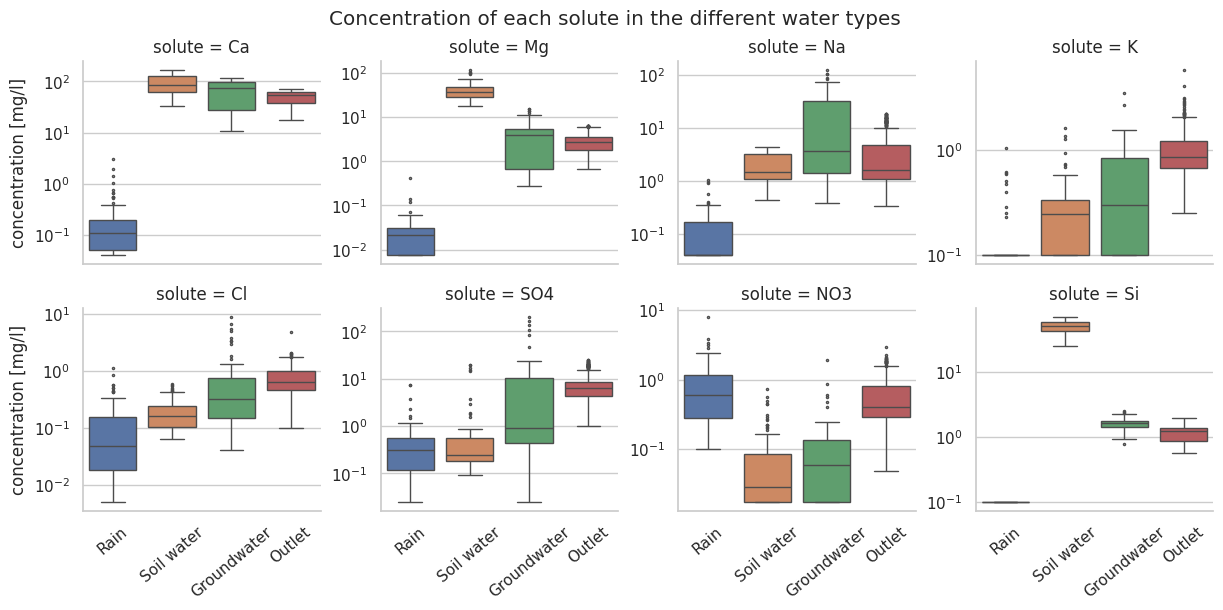

In [8]:
# Long format for plotting: one row per sample and solute
df_plot = pd.melt(df, id_vars=["location_id", "group", "subcatchment"], value_vars=solutes,
                  var_name="solute", value_name="concentration")

# One panel per solute, one box per water type (log scale: values span 4 orders of magnitude)
order = ["Rain", "Soil water", "Groundwater", "Outlet"]
g = sns.catplot(
    data=df_plot, kind="box",
    x="group", y="concentration", col="solute", col_wrap=4,
    order=order, hue="group", hue_order=order,
    sharey=False, height=2.8, aspect=1.1, fliersize=1.5,
)
for ax in g.axes.flat:
    ax.set_yscale("log")
    ax.tick_params(axis="x", rotation=40)
g.set_axis_labels("", "concentration [mg/l]")
g.fig.suptitle("Concentration of each solute in the different water types", y=1.02)
plt.show()

In [9]:
# Median composition of each water type and sub-catchment
df.groupby(["group", "subcatchment"])[solutes].median().round(2)

type                               Ca     Mg     Na     K    Cl   SO4   NO3  \
group       subcatchment                                                      
Groundwater Chaspersboden (C)   22.62   0.53   1.34  0.10  0.25  0.85  0.06   
            Langried (L)        89.17   5.32  31.77  0.65  0.57  8.12  0.06   
Outlet      Chaspersboden (C)   57.42   2.68   1.36  1.01  0.60  5.77  0.30   
            Langried (L)        46.46   3.12   4.86  0.80  0.75  8.74  0.80   
Rain        -                    0.11   0.02   0.04  0.10  0.05  0.31  0.60   
Soil water  Chaspersboden (C)   65.87  39.50   1.05  0.10  0.18  0.33  0.08   
            Langried (L)       122.63  35.27   2.80  0.30  0.14  0.24  0.02   

type                              Si  
group       subcatchment              
Groundwater Chaspersboden (C)   1.55  
            Langried (L)        1.72  
Outlet      Chaspersboden (C)   1.23  
            Langried (L)        1.07  
Rain        -                   0.10  
Soil water  Chaspersboden (C)  53.49  
            Langried (L)       43.74

In [10]:
# How much more concentrated is chloride in the stream than in the rain?
cl_rain = df.loc[df["group"] == "Rain", "Cl"].median()
cl_out = df[df["group"] == "Outlet"].groupby("location_id")["Cl"].median()
print(f"Median Cl in rain: {cl_rain:.2f} mg/l")
for loc, v in cl_out.items():
    print(f"Median Cl at {loc}: {v:.2f} mg/l  ->  {v / cl_rain:.0f} times the rain")

Median Cl in rain: 0.05 mg/l
Median Cl at CB1: 0.59 mg/l  ->  12 times the rain
Median Cl at L1: 0.75 mg/l  ->  16 times the rain


### Activity 1: Discussion

- **Rain** is almost pure water (Ca ≈ 0.1 mg/l). Only **NO3** is as high in rain (~0.6 mg/l) as in the streams.
- **Soil water** (lysimeters) is very rich in **Mg** (~35–40 mg/l) and **Si** (~45–55 mg/l) but has almost no SO4 or NO3. This is weathering in the soil plus nitrate uptake by plants and microbes.
- **Groundwater** differs strongly between the two sub-catchments. In Langried it is rich in Ca, **Na and SO4** (up to >100 mg/l SO4 in one well), probably from gypsum or evaporite minerals in the bedrock. In Chaspersboden it is dilute (Ca ~20 mg/l), even lower than the stream, so these shallow piezometers do not represent the water feeding the outlet at low flow.
- **The outlets** lie between these water types. L1 has more Na and SO4 than CB1, which matches its Na- and SO4-rich groundwater.
- **Chloride** is about **12–16 times more concentrated in the streams than in rain**. As at Plynlimon (Exercise 2), this points to **evapoconcentration** (evapotranspiration removes water, not Cl) and **dry deposition** on vegetation. Rain Cl is close to the detection limit, so the factor is only indicative.

---
### Activity 2: Problem formulation

In the Plynlimon exercise, solutes from the subsoil (Si, Ca) were **diluted** at high flow, while solutes from the organic soil (DOC, Al) **increased**. We have no discharge here, but **Ca is a good indicator of how much rain water is in the stream**: it is high at baseflow and drops strongly during events (rain has almost no Ca). Which solutes follow Ca (diluted), and which behave the opposite way (mobilised during events)?

To compare solutes with different units and ranges, we normalise each one per outlet (subtract the mean and divide by the standard deviation), as in the Hupsel exercise.

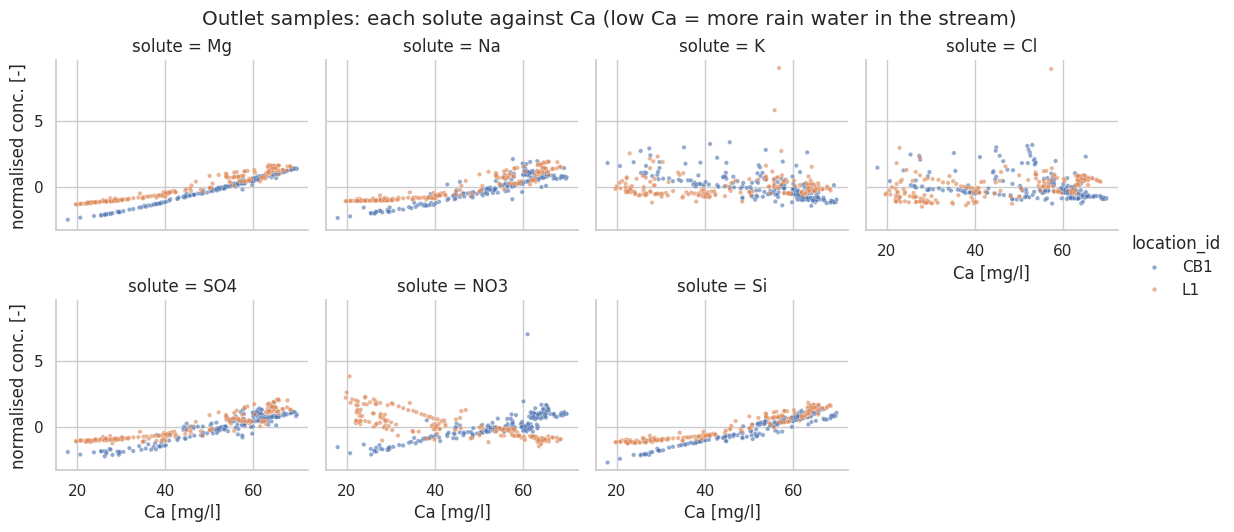

In [11]:
# Outlet samples only
df_out = df[df["group"] == "Outlet"].copy()

# Normalise each solute per outlet: (x - mean) / std
def normalize(x):
    return (x - x.mean()) / x.std()

for s in solutes:
    df_out[s + "_norm"] = df_out.groupby("location_id")[s].transform(normalize)

# Long format: every solute against Ca
others = [s for s in solutes if s != "Ca"]
df_cc = pd.melt(df_out, id_vars=["location_id", "collected_at", "Ca"],
                value_vars=[s + "_norm" for s in others], var_name="solute", value_name="norm_conc")
df_cc["solute"] = df_cc["solute"].str.replace("_norm", "")

g = sns.relplot(
    data=df_cc, kind="scatter",
    x="Ca", y="norm_conc", col="solute", col_wrap=4, hue="location_id",
    s=10, alpha=0.6, height=2.6, aspect=1.1,
)
g.set_axis_labels("Ca [mg/l]", "normalised conc. [-]")
g.fig.suptitle("Outlet samples: each solute against Ca (low Ca = more rain water in the stream)", y=1.02)
plt.show()

In [12]:
# Spearman correlation of each solute with Ca, per outlet
# positive: diluted during events like Ca; negative: higher during events
corr_ca = pd.DataFrame({
    loc: {s: stats.spearmanr(d["Ca"], d[s], nan_policy="omit").statistic for s in others}
    for loc, d in df_out.groupby("location_id")
}).round(2)
corr_ca.T

,Mg,Na,K,Cl,SO4,NO3,Si
CB1,0.99,0.85,-0.75,-0.53,0.87,0.89,0.94
L1,0.97,0.95,0.12,0.50,0.93,-0.86,0.96


Now look at how this plays out in time during the two largest events (16 and 19 September), with normalised concentrations so all solutes fit on one axis.

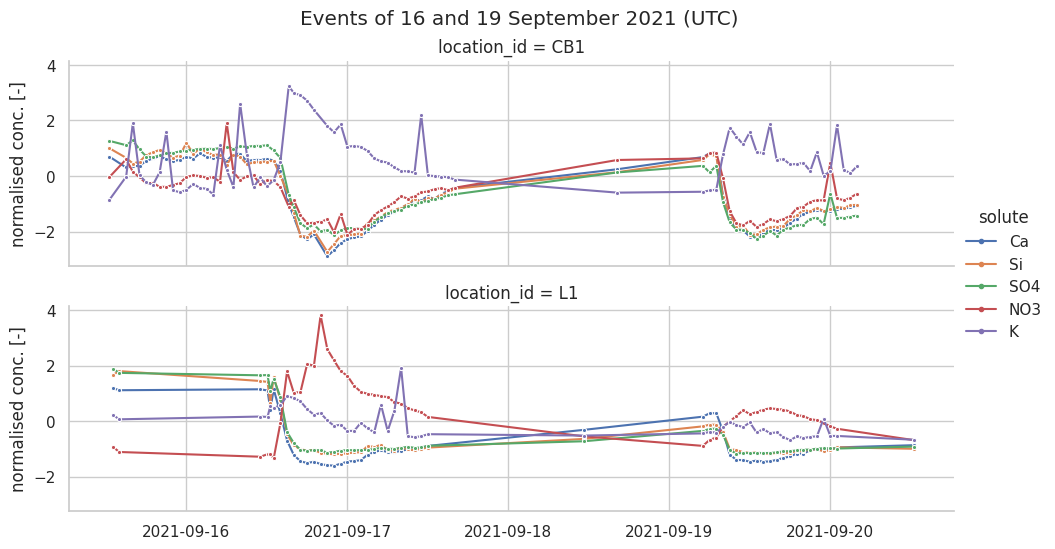

In [13]:
q = (df_out["collected_at"] >= "2021-09-15 12:00") & (df_out["collected_at"] < "2021-09-21")
show = ["Ca", "Si", "SO4", "NO3", "K"]
df_ts = pd.melt(df_out[q], id_vars=["location_id", "collected_at"],
                value_vars=[s + "_norm" for s in show], var_name="solute", value_name="norm_conc")
df_ts["solute"] = df_ts["solute"].str.replace("_norm", "")

g = sns.relplot(
    data=df_ts, kind="line",
    x="collected_at", y="norm_conc", hue="solute", row="location_id",
    height=2.8, aspect=3.5, marker="o", markersize=3,
)
g.set_axis_labels("", "normalised conc. [-]")
g.fig.suptitle("Events of 16 and 19 September 2021 (UTC)", y=1.02)
plt.show()

### Activity 2: Discussion

Two groups of solutes appear, as in the Plynlimon exercise:

- **Diluted during events (geogenic solutes):** **Mg, Si, Na and SO4** correlate strongly and positively with Ca at both outlets (ρ ≈ 0.85–0.99). They come from mineral weathering in the soil and bedrock and are highest in pre-event water. When rain water arrives, they are all diluted together.
- **Higher during events (soil- and vegetation-derived solutes):**
  - **K** at CB1 (ρ = −0.75) rises during events. Potassium is leached from leaves, litter and the organic topsoil, so it is flushed out when water flows through or over the topsoil.
  - **NO3** at L1 (ρ = −0.86) rises during events, to about 3–4 times the rain concentration. Nitrate stored in the topsoil is mobilised by the event water.
  - **Cl** at CB1 (ρ = −0.53) also increases slightly during events, which suggests Cl stored in the topsoil or deposited on vegetation is washed out.
- **The two sub-catchments differ for nitrate.** At CB1, NO3 is *diluted* like Ca (ρ = 0.89) and drops below the rain concentration, so rain nitrate is probably taken up or removed in the soil before reaching the stream. At L1 it is mobilised. The same solute can be removed in one place and flushed in another, depending on flow paths and soil conditions.

The response is fast: concentrations change within 1–2 hours of the rain and recover over the following day. This means the event water reaches the stream along **shallow flow paths** (overland flow and flow through the topsoil), which are typical of these waterlogged soils.

---
### Activity 3: Problem formulation

If stream water is a mixture of two sources with roughly constant concentrations, the fraction of each source can be computed with a linear mixing formula, as in Exercise 2:

$$f_{pre} = \frac{C_{stream} - C_{rain}}{C_{pre} - C_{rain}}, \qquad f_{event} = 1 - f_{pre}$$

Here the two sources are **pre-event water** (the water stored in the catchment before the rain) and **event water** (rain). What fraction of the stream water is rain water during events? Do Ca, Mg and Si give consistent answers?

**End members.**
- **Rain:** the median of the E2 samples.
- **Pre-event water:** following the hint from Exercise 2, we take *typical high stream concentrations* (95th percentile at each outlet). The groundwater wells are not used, because at Chaspersboden they have lower Ca than the stream itself (Activity 1).

In [14]:
tracers = ["Ca", "Mg", "Si"]
C_rain = df.loc[df["group"] == "Rain", tracers].median()

frames = []
for loc, d in df_out.groupby("location_id"):
    d = d.copy()
    C_pre = d[tracers].quantile(0.95)          # pre-event end member for this outlet
    for s in tracers:
        d["f_pre_" + s] = (d[s] - C_rain[s]) / (C_pre[s] - C_rain[s])
    print(f"{loc}: pre-event end member = {C_pre.round(2).to_dict()} | rain = {C_rain.round(2).to_dict()}")
    frames.append(d)
df_mix = pd.concat(frames)

# Summary: median and minimum pre-event fraction (the minimum is the peak of event water)
df_mix.groupby("location_id")[["f_pre_" + s for s in tracers]].agg(["median", "min"]).round(2)

CB1: pre-event end member = {'Ca': 67.17, 'Mg': 3.37, 'Si': 1.4} | rain = {'Ca': 0.11, 'Mg': 0.02, 'Si': 0.1}
L1: pre-event end member = {'Ca': 65.5, 'Mg': 6.16, 'Si': 1.81} | rain = {'Ca': 0.11, 'Mg': 0.02, 'Si': 0.1}


type        f_pre_Ca       f_pre_Mg       f_pre_Si      
              median   min   median   min   median   min
location_id                                             
CB1             0.85  0.27     0.79  0.20     0.87  0.44
L1              0.71  0.30     0.50  0.15     0.57  0.28

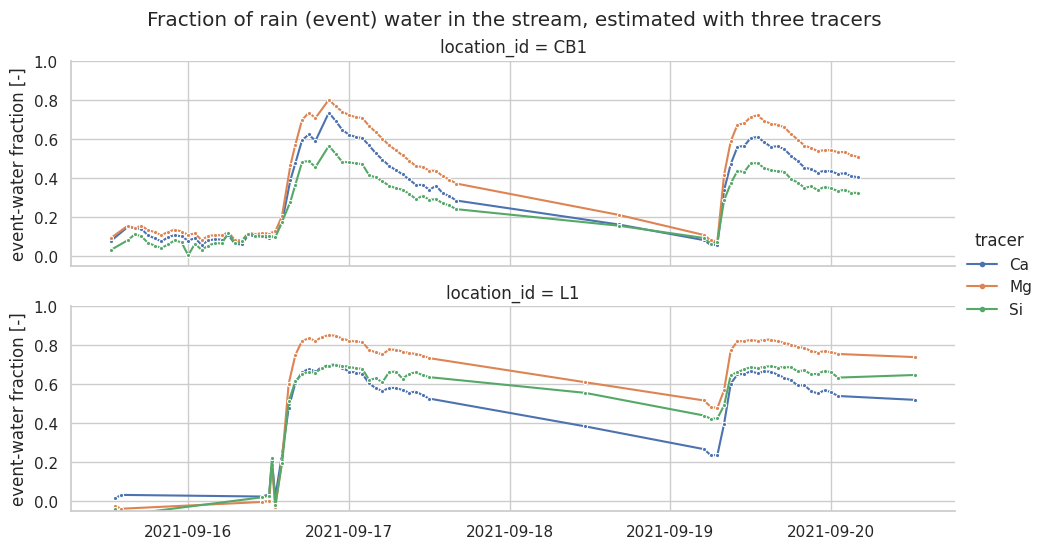

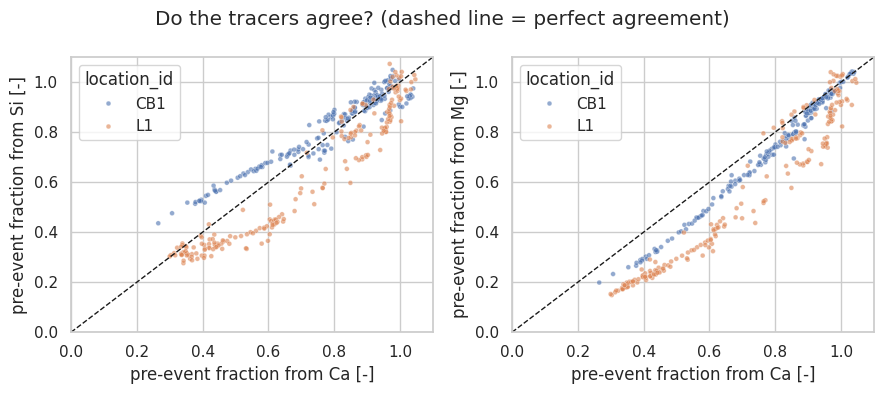

In [15]:
# Time series of the event-water fraction for the September events
q = (df_mix["collected_at"] >= "2021-09-15 12:00") & (df_mix["collected_at"] < "2021-09-21")
df_f = pd.melt(df_mix[q], id_vars=["location_id", "collected_at"],
               value_vars=["f_pre_" + s for s in tracers], var_name="tracer", value_name="f_pre")
df_f["tracer"] = df_f["tracer"].str.replace("f_pre_", "")
df_f["f_event"] = 1 - df_f["f_pre"]

g = sns.relplot(
    data=df_f, kind="line",
    x="collected_at", y="f_event", hue="tracer", row="location_id",
    height=2.8, aspect=3.5, marker="o", markersize=3,
)
g.set(ylim=(-0.05, 1))
g.set_axis_labels("", "event-water fraction [-]")
g.fig.suptitle("Fraction of rain (event) water in the stream, estimated with three tracers", y=1.02)
plt.show()

# Consistency between tracers: Ca-based vs Si-based and Mg-based estimates
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, s in zip(axes, ["Si", "Mg"]):
    sns.scatterplot(data=df_mix, x="f_pre_Ca", y="f_pre_" + s, hue="location_id", s=12, alpha=0.6, ax=ax)
    ax.plot([0, 1.1], [0, 1.1], "k--", lw=1)
    ax.set(xlabel="pre-event fraction from Ca [-]", ylabel=f"pre-event fraction from {s} [-]",
           xlim=(0, 1.1), ylim=(0, 1.1))
fig.suptitle("Do the tracers agree? (dashed line = perfect agreement)")
fig.tight_layout()
plt.show()

### Activity 3: Discussion

- **Most of the time the outlets carry pre-event water** (median pre-event fraction 0.85 at CB1 and 0.71 at L1, based on Ca). During the 16 and 19 September events, the **event-water fraction rises within 2–3 hours to about 0.6–0.75 (Ca)** and then decreases slowly over the following day.
- **At CB1, Ca and Mg agree closely.** Si gives a somewhat lower event-water fraction at the peak (about 0.55 instead of 0.73). Event water probably picks up some Si on its way, since soil water is extremely rich in Si (Activity 1).
- **At L1 the tracers disagree more:** Mg gives the highest event-water fraction (up to 0.85), and the Mg–Ca and Si–Ca relations are curved. A third source with different Mg/Ca and Si/Ca ratios is probably involved, for example the Na- and SO4-rich groundwater (Activity 1). The two-component model is then only an approximation, and the spread between tracers (0.7–0.85 at the peak) is a fair measure of its uncertainty.
- **Why is the event-water fraction so high?** In catchments with deep, permeable soils, stream water during events is usually dominated by old pre-event water. Here the soils are waterlogged gleysols with low permeability, so a large part of the rain runs off quickly over or through the topsoil (Activity 2) and reaches the stream with little time to mix with stored water.

### Limitations
- The file has no discharge, so we cannot compute loads or C–Q relationships. Ca is used as a proxy for the share of rain water.
- End members are assumed constant. Rain chemistry varies during an event, and "event water" may pick up solutes on its way, so the event-water fraction is better read as the "fraction of dilute water".
- Many rain values (Ca, Mg 40 %, Si 100 %) are below the detection limit and replaced by LOD/2. Rain concentrations are so low that this barely affects the mixing fractions.

## References
- Bujak, I., von Freyberg, J., Rinaldo, A. and van Meerveld, I.: Hydrochemical data collected during spring–fall 2021 in the Erlenbach catchment, EnviDat.
- Neal, C. et al. (2012): High-frequency precipitation and stream water quality time series from Plynlimon, Wales, *Sci. Total Environ.*, https://doi.org/10.1016/j.scitotenv.2011.10.072 (dilution of geogenic solutes and flushing of soil-derived solutes; Exercise 2).
- Neal, C. and Kirchner, J. W. (2000): Sodium and chloride levels in rainfall, mist, streamwater and groundwater at the Plynlimon catchments, *Hydrol. Earth Syst. Sci.*, 4, 295–310, https://doi.org/10.5194/hess-4-295-2000 (evapoconcentration and dry deposition of Cl; Exercise 2).
- Add the course and literature references provided by your instructor here.